## Example Notebook

This notebook demonstrates how to use `popkinmocks` to generate the counter-rotating galaxy used in the work "3D Full Spectrum Fitting: Algorithm Comparison". Full documentation can be found at [here](https://popkinmocks.readthedocs.io/en/stable/).

In [1]:
import popkinmocks as pkm
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(301288)

First load the SSPS and create the IFU cube.

In [2]:
ssps = pkm.model_grids.milesSSPs(
    lmd_min=4800,
    lmd_max=5700,
    age_lim=(0.5, 15)
    )

cube = pkm.ifu_cube.IFUCube(
    ssps=ssps, 
    nx1=30,
    nx2=30,
    x1rng=(2,8),
    x2rng=(-3,3),
    vrng=(-750.,750.),
    nv=41)

Define the two disk components, first the thick disk.

In [3]:
thick_disk = pkm.components.GrowingDisk(cube=cube, rotation=0., center=(0,0))
thick_disk.set_p_t(lmd=20., phi=0.8)
thick_disk.set_p_x_t(
    q_lims=(0.3, 0.9),
    rc_lims=(5., 3),
    alpha_lims=(1.2, 0.8)
    )
thick_disk.set_t_dep(q=0.5, alpha=1., t_dep_in=10., t_dep_out=12.)
thick_disk.set_mu_v(
    q_lims=(0.8, 1.),
    rmax_lims=(6., 4.),
    vmax_lims=(200., 150.)
)
thick_disk.set_sig_v(
    q_lims=(0.5, 0.8),
    alpha_lims=(1.0, 1.8),
    sig_v_in_lims=(120., 130.),
    sig_v_out_lims=(100., 110.))

Then the counter-rotating thin disk.

In [4]:
thin_disk = pkm.components.GrowingDisk(cube=cube, rotation=0, center=(0.,0.))
thin_disk.set_p_t(lmd=10., phi=0.3)
thin_disk.set_p_x_t(
    q_lims=(0.1, 0.2),
    rc_lims=(4., 3.),
    alpha_lims=(0.6, 0.9)
    )
thin_disk.set_t_dep(q=0.3, alpha=1., t_dep_in=0.5, t_dep_out=4.)
thin_disk.set_mu_v(
    q_lims=(0.15, 0.2),
    rmax_lims=(7., 2.),
    vmax_lims=(-350., -350.)
)
thin_disk.set_sig_v(
    q_lims=(0.4, 0.6),
    alpha_lims=(1.2, 1.5),
    sig_v_in_lims=(75., 100.),
    sig_v_out_lims=(60., 80.))

Combine the two as a `Mixture` component, with equal weights.

In [5]:
galaxy = pkm.components.Mixture(
    cube=cube,
    component_list=[thick_disk, thin_disk],
    weights=[0.5, 0.5],
    )


To visualise the model:
- use the methods `galaxy.get_p` to evaluate density distributions and `galaxy.get_mean` to get distributions means
- use `cube.imshow` to plot the resulting images with appropriate axes

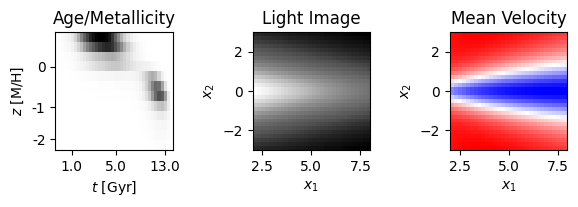

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(6,2))

age_metal_dist = galaxy.get_p('tz')
cube.imshow(age_metal_dist, view='tz', ax=ax[0], cmap=plt.cm.Greys, colorbar=False)

light_image = galaxy.get_p('x', light_weighted=True)
cube.imshow(light_image, ax=ax[1], cmap=plt.cm.Greys_r, colorbar=False)

mean_velocity_map = galaxy.get_mean('v_x', light_weighted=True)
cube.imshow(mean_velocity_map, ax=ax[2], cmap=plt.cm.bwr, colorbar=False)

ax[0].set_title('Age/Metallicity')
ax[1].set_title('Light Image')
ax[2].set_title('Mean Velocity')

fig.tight_layout()

Evalaute the noise free datacube.

In [7]:
thick_disk.evaluate_ybar()
thin_disk.evaluate_ybar()
galaxy.evaluate_ybar()

Add shot noise with a desired SNR.

In [8]:
snr_arr = 200.
shot_noise = pkm.noise.ShotNoise(galaxy)
yobs = shot_noise.get_noisy_data(snr=100)

Plot the spectrum from a chosen spaxel

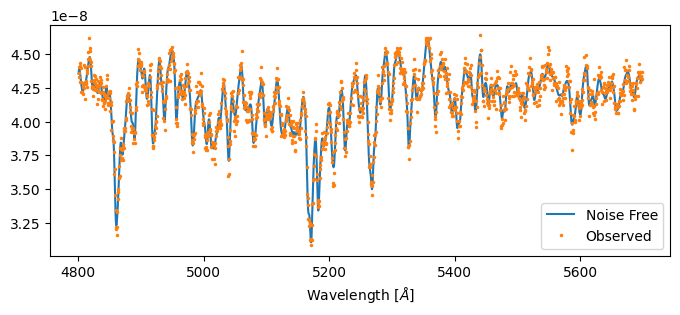

In [9]:
i, j = 5, 5 # spaxel

fig, ax = plt.subplots(1,1, figsize=(8,3))
plt.sca(ax)
cube.plot_spectrum(galaxy.ybar[:,i,j], '-', label='Noise Free')
cube.plot_spectrum(yobs[:,i,j], '.', ms=3, label='Observed')
plt.gca().legend()